# Delegação na fonte e fechamento das evidências

10 minutos + extensão

[Objetivos e sequência de aprendizagem](../docs/jornada.md).
Execute com o kernel Python de `.venv`.

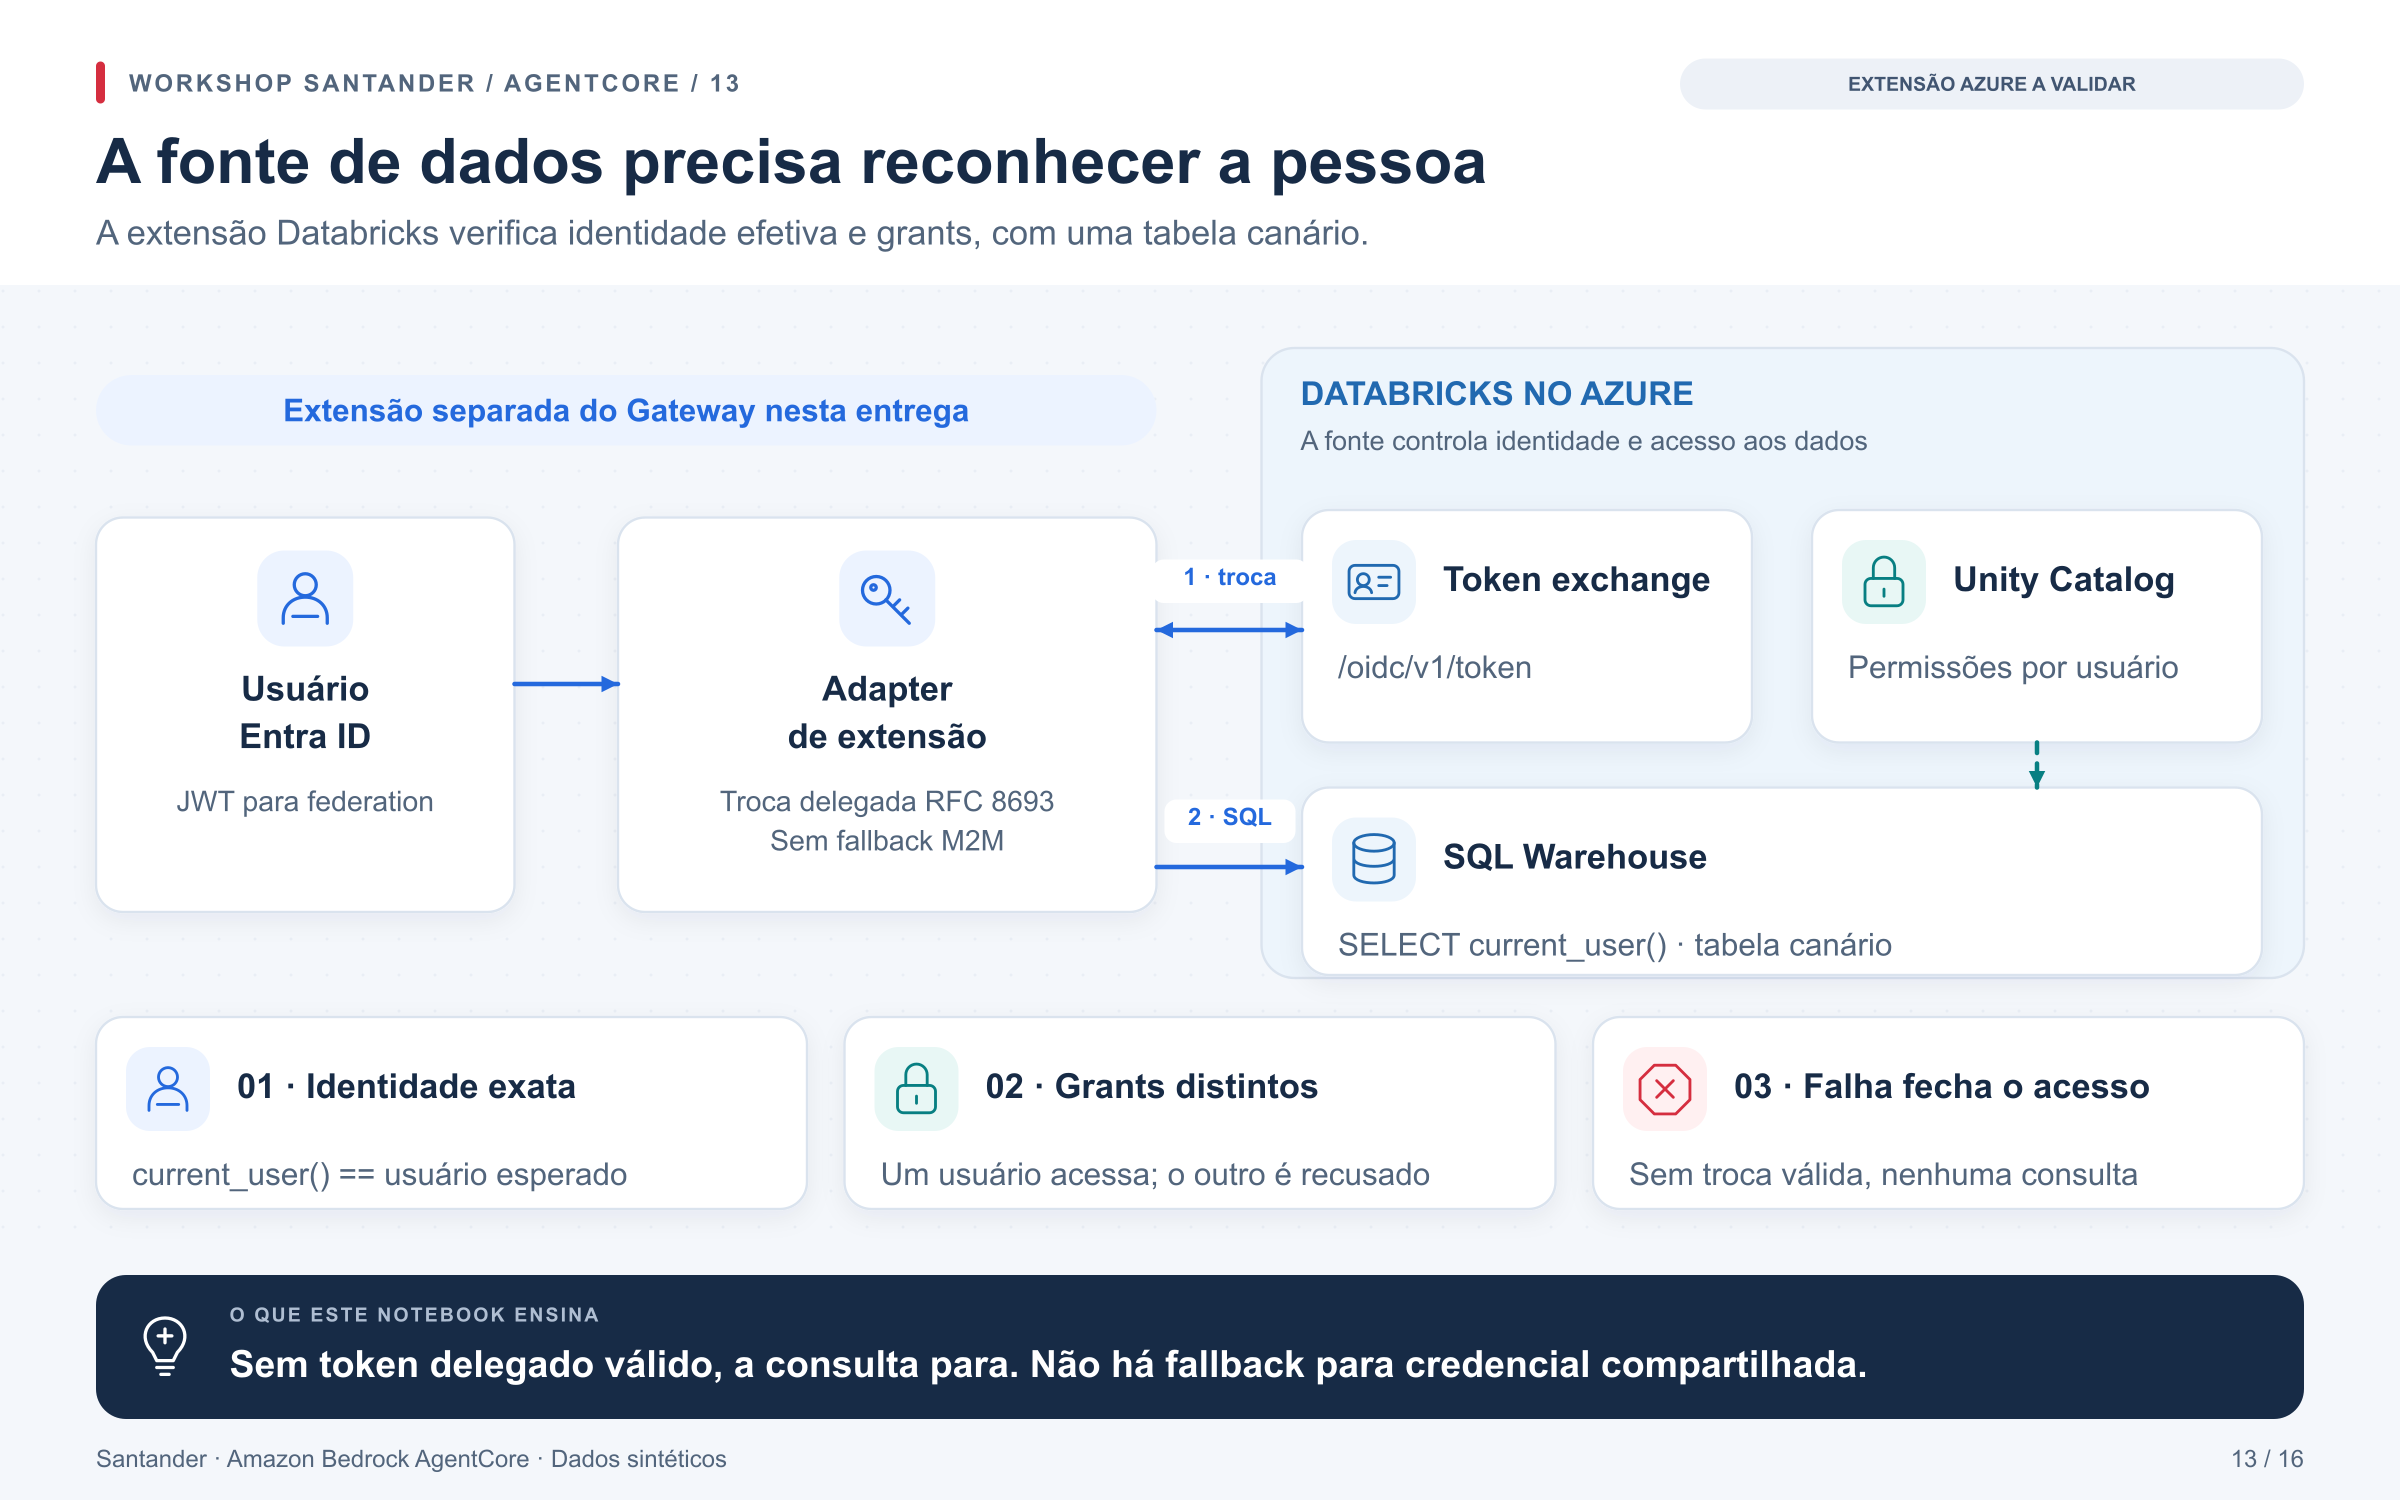

**Objetivo visual:** Provar current_user() exato e acesso distinto para dois usuários na mesma tabela sintética.

[Abrir PNG](../docs/diagramas/png/13_databricks_e_evidencias.png) · [SVG editável](../docs/diagramas/svg/13_databricks_e_evidencias.svg) · [Galeria dos notebooks](../docs/diagramas/index.html)

**Etapa 14 de 17 na jornada.** [Jornada completa](../docs/jornada.md) · [Anterior: Gateway por conta](12_gateways_por_conta_identity_policy.ipynb) · [Próximo: Cenário integrado](14_cenario_santander_integrado.ipynb)

## Conceitos para acompanhar este laboratório

**Federação** permite que o destino confie num provedor de identidade externo.
**Token exchange** troca essa credencial por outra aceita pelo Databricks.
O **SQL Warehouse** executa SQL; **Unity Catalog** controla permissões
como `SELECT` sobre os dados.

`current_user()` mostra quem a fonte reconheceu, enquanto uma consulta
à tabela canário verifica um grant específico. São duas provas distintas:
login válido não garante acesso à tabela. Uma tabela **canário** contém
dados sintéticos preparados para tornar esse teste observável.

`DelegatedDatabricks.prove()` em
[databricks.py](../src/santander_demo/databricks.py) compara a identidade
exata e verifica sucesso ou um código de permissão esperado. A consulta
usa `SELECT 1 ... LIMIT 1`; o objetivo é provar acesso, sem exibir os dados.

**Documentação oficial para aprofundar:**

* [Databricks: função current_user](https://learn.microsoft.com/pt-br/azure/databricks/sql/language-manual/functions/current_user)
* [Databricks: API SQL Statement Execution](https://learn.microsoft.com/pt-br/azure/databricks/dev-tools/sql-execution-tutorial)
* [Unity Catalog: gerenciamento de privilégios](https://learn.microsoft.com/pt-br/azure/databricks/data-governance/unity-catalog/manage-privileges/)

As explicações estão em português; nomes de APIs, claims e campos permanecem como aparecem no código. As páginas oficiais podem estar em inglês.

### Preparar o ambiente deste notebook

Vamos importar os componentes do workshop, localizar a pasta do projeto e ler
`WORKSHOP_MODE`, cujo padrão é `local`. A instância `lab` reúne o emissor de
tokens de teste, o catálogo em memória, as políticas Cedar e o registro de
evidências que serão usados nas próximas células.

Se o modo for `aws`, também carregaremos `config/local.json` e inicializaremos
o cliente do ambiente configurado. Ao final, a mensagem mostrará o modo ativo;
`LOCAL_SIMULATION` indica que os resultados locais não comprovam a integração
com AWS ou Entra. Reexecutar esta célula reinicia o estado local do laboratório.

In [ ]:
import os
from pathlib import Path
from santander_demo.local import Workshop
from santander_demo.contracts import CLIENTE, DemoError

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
MODE = os.environ.get("WORKSHOP_MODE", "local")
assert MODE in {"local", "aws"}, "WORKSHOP_MODE deve ser local ou aws"
lab = Workshop()
cloud = None
if MODE == "aws":
    from santander_demo.config import Environment
    from santander_demo.cloud import CloudWorkshop
    config = Environment.load(ROOT / "config/local.json")
    cloud = CloudWorkshop(config)
print("LOCAL_SIMULATION — nenhuma prova de AWS/Entra" if MODE == "local" else "AWS — integração real")

Esta é uma prova isolada por SQL REST. O fluxo integrado Gateway → MCP DBSQL
está no [notebook 14](14_cenario_santander_integrado.ipynb).

Esta extensão exige federation de usuários no nível da conta Databricks,
token exchange, um warehouse Azure e uma tabela canário sintética com grants distintos.
A preparação desses recursos deve seguir o IaC do cliente. O projeto não altera
Unity Catalog, BDAGs ou permissões do cliente.

O adapter recusa token ausente, troca inválida e principal divergente. Não há
fallback para service principal. Formato de email não comprova identidade.

### Comprovar o usuário delegado e o acesso à tabela canário

Esta etapa só será executada com `WORKSHOP_MODE=aws` e
`RUN_DATABRICKS=true`. Vamos conferir os parâmetros do workspace,
solicitar o JWT Entra com entrada oculta e usar o adapter para
realizar a troca de token e consultar o SQL Warehouse.

O helper deverá comprovar que `current_user()` coincide exatamente
com o usuário esperado e que ele consegue acessar a tabela canário
configurada. Após a chamada, a variável do JWT será removida.
Sem os dois controles ativos, Databricks e grants ficarão como `NOT_RUN`.

In [ ]:
proof = None
if MODE == "aws" and os.environ.get("RUN_DATABRICKS") == "true":
    from getpass import getpass
    from santander_demo.databricks import DelegatedDatabricks
    assert all([config.databricks_host, config.databricks_warehouse,
                config.expected_databricks_user, config.databricks_canary_table])
    delegated = DelegatedDatabricks(config.databricks_host,
        config.databricks_warehouse, config.expected_databricks_user)
    user_jwt = getpass("Token Entra para a federation do Databricks: ")
    try:
        proof = delegated.prove(user_jwt, config.databricks_canary_table,
                                expect_grant=True)
    finally:
        del user_jwt
        delegated.http.close()
    print(proof)
else:
    print({"databricks_azure": "NOT_RUN", "unity_catalog_grants": "NOT_RUN"})

### Salvar as evidências dos testes locais

Vamos executar novamente a matriz de autorização para registrar seus
resultados no coletor local. Em seguida, exportaremos as evidências
em JSON para `evidence/local-notebook.json`, criando a pasta caso
necessário e substituindo esse arquivo se ele já existir.

A saída mostrará o caminho salvo e `LOCAL_SIMULATION`. O arquivo
documenta os testes de `lab`, inclusive quando o notebook está no
modo AWS. A prova Databricks, se executada, será salva separadamente
em `evidence/databricks-rest-live.json`, sem token ou e-mail.

In [ ]:
import json
lab.policy_matrix()
target = ROOT / "evidence/local-notebook.json"
target.parent.mkdir(exist_ok=True)
target.write_text(json.dumps(lab.evidence.export(), ensure_ascii=False, indent=2))
print({"evidence": str(target), "mode": "LOCAL_SIMULATION"})
if proof is not None:
    (ROOT / "evidence/databricks-rest-live.json").write_text(
        json.dumps(proof, ensure_ascii=False, indent=2) + "\n")

Repita a prova Databricks com usuário sem grant e `expect_grant=False`. O helper
exige erro de permissão, não aceita erro SQL genérico como evidência.
Para fechar: complete `docs/validacao.md`, separe PASS local de PASS AWS e remova
outputs de notebooks interativos que possam conter informações do ambiente.

## Limpeza — recursos do laboratório

Os notebooks **00–06, 08, 10 e 13 compartilham o ambiente**. Remova os stacks somente
ao encerrar toda a trilha, depois de salvar as evidências.

1. Atualize `origin` com `EnableRuntime=false` pelo `scripts/deploy.py`.
2. Remova `registry`; preserve o output de `policy-draft`, se utilizado,
   antes de remover seu stack. O histórico de geração usa `Retain`.
3. Atualize `hub` com `EnableFraud=false` pelo `scripts/deploy.py`.
4. Remova `fraud-runtime`, depois `hub` e, por último, `origin`.
5. Remova os stacks `bootstrap` somente após revisar os artefatos retidos.

Para cada remoção, use o template correspondente e o **nome real do stack**
implantado. Os nomes de template acima não determinam os nomes dos stacks.
Buckets usam `Retain`; aplicações e segredos Entra seguem o Terraform que os
gerencia. O notebook 13 não é proprietário do workspace, warehouse ou grants
Databricks. Consulte o [runbook da trilha](../docs/deploy.md#9-limpeza).

**Na próxima célula**, `CLEANUP_TARGET=None` manterá a remoção desativada e
imprimirá `cloud_cleanup: NOT_RUN`. Para revisar um stack real, preencha o
alvo indicado no comentário e mantenha `CLEANUP_EXECUTE=False`. O script
`scripts/cleanup.py` consultará STS e CloudFormation, exigirá correspondência
exata entre template implantado e fonte local e mostrará o ARN, as retenções
declaradas e eventuais bloqueios. Essa preparação faz somente leituras.

Após revisar o plano e a ordem acima, copie seu ARN para
`CLEANUP_CONFIRM_STACK_ID` e habilite `CLEANUP_EXECUTE` para remover **esse
stack** pelo wrapper IaC. O script aguarda a exclusão pelo CloudFormation,
respeita `Retain` e não desativa proteções. Falhas devem ser resolvidas no
IaC. A execução padrão deste notebook não remove recursos em nuvem.

In [ ]:
import subprocess as _cleanup_subprocess
import sys as _cleanup_sys

# Preencha somente para um stack do laboratório, após encerrar a trilha:
# {"template": "TEMPLATE", "stack": "NOME_REAL", "profile": "PERFIL",
#   "account": "ID_DA_CONTA", "region": "REGIAO"}
CLEANUP_TARGET = None
CLEANUP_EXECUTE = False
CLEANUP_CONFIRM_STACK_ID = ""

if CLEANUP_TARGET is None:
    print({"cloud_cleanup": "NOT_RUN", "reason": "Nenhum stack selecionado"})
else:
    assert set(CLEANUP_TARGET) == {"template", "stack", "profile", "account", "region"}
    _cleanup_command = [
        _cleanup_sys.executable, str(ROOT / "scripts/cleanup.py"),
        "--scenario", "workshop",
    ]
    for _cleanup_key, _cleanup_value in CLEANUP_TARGET.items():
        _cleanup_command.extend(["--" + _cleanup_key, _cleanup_value])
    if CLEANUP_EXECUTE:
        assert CLEANUP_CONFIRM_STACK_ID, "Revise o plano e informe o ARN exato do stack"
        _cleanup_command.extend(["--execute", "--confirm-stack-id", CLEANUP_CONFIRM_STACK_ID])
    _cleanup_subprocess.run(_cleanup_command, cwd=ROOT, check=True)

### Limpeza — estado local do notebook

Vamos remover as variáveis de dados, tokens, clientes e configuração criadas
por este exercício. As sessões MCP abertas com `async with` já foram encerradas
ao sair de seus blocos; o cliente de controle de `cloud`, quando presente,
também será fechado. A célula verificará que os nomes listados deixaram
de existir e exibirá `cleanup_local: PASS`; ela pode ser repetida.

Os notebooks, diagramas, templates e arquivos de evidências serão preservados.
Esta limpeza remove referências do namespace; não revoga tokens nem apaga
outputs ou todas as cópias que possam existir na memória do processo.
Após salvar as evidências, limpe as saídas e encerre o kernel para terminar
a sessão. Para repetir o laboratório, recomece pela preparação do ambiente.

In [ ]:
import json as _cleanup_json

if globals().get("cloud") is not None:
    cloud.control.close()
_cleanup_names = ['CLEANUP_CONFIRM_STACK_ID', 'CLEANUP_EXECUTE', 'CLEANUP_TARGET', 'MODE',
 '_cleanup_command', '_cleanup_key', '_cleanup_subprocess', '_cleanup_sys',
 '_cleanup_value', 'cloud', 'config', 'delegated', 'identity', 'lab', 'proof', 'target',
 'token', 'user_jwt']
_cleanup_removed = [name for name in _cleanup_names if name in globals()]
for _cleanup_name in _cleanup_names:
    globals().pop(_cleanup_name, None)
assert not any(name in globals() for name in _cleanup_names)
print(_cleanup_json.dumps({
    "cleanup_local": "PASS",
    "removed_variables": len(_cleanup_removed),
    "files": "PRESERVED",
}, ensure_ascii=False))
del _cleanup_name, _cleanup_names, _cleanup_removed, _cleanup_json